# Statistical Analysis Notebook

#### Sanity checks and initial set up, these are just me making sure everything actually exists, is valid, and can be replicated for all 35 videos. Basically just a bunch of sanity checks and ensuring the right column name extraction

In [ ]:
#setup and init for imports and finding paths
from pathlib import Path
import pandas as pd
import numpy as np

#change path if running on diff local machine
PROJECT_DIR = Path(
    "/Users/emmy/OneDrive - Virginia Tech/sports proj3"
)

LABELS_PATH = PROJECT_DIR / "kick_labels.csv"
SPEEDS_PATH = PROJECT_DIR / "kick_speeds.csv"
POSE_DIR = PROJECT_DIR / "pose_results"

#sanity 
for path in [LABELS_PATH, SPEEDS_PATH, POSE_DIR]:
    print(f"{path.name}: {'Found' if path.exists() else 'MISSING'}")

kick_labels.csv: Found
kick_speeds.csv: Found
pose_results: Found


In [ ]:
# reading everything in
labels = pd.read_csv(LABELS_PATH, keep_default_na=False)
speeds = pd.read_csv(SPEEDS_PATH, keep_default_na=False)

print("Labels:", labels.shape)
print("Label columns:", labels.columns.tolist())

print("\nSpeeds:", speeds.shape)
print("Speed columns:", speeds.columns.tolist())

display(labels.head())
display(speeds.head())

Labels: (35, 9)
Label columns: ['video', 'player', 'contact_frame', 'net_contact_frame', 'reported_fps', 'contact_to_net_seconds_approx', 'outcome', 'touch_before_net', 'foot']

Speeds: (35, 14)
Speed columns: ['video', 'player', 'contact_frame', 'net_contact_frame', 'reported_fps', 'contact_to_net_seconds_approx', 'outcome', 'touch_before_net', 'flight_time_seconds', 'estimated_speed_mps', 'estimated_speed_mph', 'estimated_speed_kph', 'assumed_distance_yards', 'direct_flight_candidate']


,video,player,contact_frame,net_contact_frame,reported_fps,contact_to_net_seconds_approx,outcome,touch_before_net,foot
0,pk vids - 1.MOV,pk vids - 1,275,308,59.975010,0.550229,Goal,,right
1,pk vids - 2.MOV,pk vids - 2,428,459,59.971214,0.516915,Goal,,right
2,pk vids - 3.MOV,pk vids - 3,447,476,59.971397,0.483564,Goal,,left
3,pk vids - 4.MOV,pk vids - 4,150,190,59.963100,0.667077,Goal,,right
4,pk vids - 5.MOV,pk vids - 5,693,728,59.972894,0.583597,Goal,,right


,video,player,contact_frame,net_contact_frame,reported_fps,contact_to_net_seconds_approx,outcome,touch_before_net,flight_time_seconds,estimated_speed_mps,estimated_speed_mph,estimated_speed_kph,assumed_distance_yards,direct_flight_candidate
0,pk vids - 1.MOV,pk vids - 1,275,308,59.975010,0.550229,Goal,,0.550229,19.942236,44.609506,71.792050,12,False
1,pk vids - 2.MOV,pk vids - 2,428,459,59.971214,0.516915,Goal,,0.516915,21.227488,47.484533,76.418958,12,False
2,pk vids - 3.MOV,pk vids - 3,447,476,59.971397,0.483564,Goal,,0.483564,22.691522,50.759483,81.689480,12,False
3,pk vids - 4.MOV,pk vids - 4,150,190,59.963100,0.667077,Goal,,0.667077,16.449077,36.795534,59.216679,12,False
4,pk vids - 5.MOV,pk vids - 5,693,728,59.972894,0.583597,Goal,,0.583597,18.802016,42.058907,67.687258,12,False


In [ ]:
# standardizing foot labels in memory (right vs left)
labels["foot"] = labels["foot"].str.strip().str.lower()

print("Kicking-foot labels:")
print(labels["foot"].value_counts(dropna=False))

print("\nDuplicate videos in labels:", labels["video"].duplicated().sum())
print("Duplicate videos in speeds:", speeds["video"].duplicated().sum())

# Convert speed values to numbers; blanks become NaN
speeds["estimated_speed_mph"] = pd.to_numeric(
    speeds["estimated_speed_mph"],
    errors="coerce"
)

#ensuring speeds exist for all vids (if not go back and recalculate based on frame selection)
print("\nVideos with missing or nonnumeric speeds:")
display(
    speeds.loc[
        speeds["estimated_speed_mph"].isna(),
        ["video", "contact_frame", "net_contact_frame",
         "reported_fps", "estimated_speed_mph"]
    ]
)

Kicking-foot labels:
foot
right    29
left      6
Name: count, dtype: int64

Duplicate videos in labels: 0
Duplicate videos in speeds: 0

Videos with missing or nonnumeric speeds:


/var/folders/m0/1q_jsr0x4yl2b4zqrkjgslph0000gn/T/ipykernel_8999/2401305472.py:11: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  speeds["estimated_speed_mph"] = pd.to_numeric(


,video,contact_frame,net_contact_frame,reported_fps,estimated_speed_mph


In [ ]:
# find all pose result csvs (shyould be 35)
pose_paths = sorted(POSE_DIR.rglob("pose.csv"))

print("Pose CSVs found:", len(pose_paths))

if not pose_paths:
    raise FileNotFoundError("No pose.csv files found inside pose_results.")

# Inspect the first file
pose_path = pose_paths[0]
pose = pd.read_csv(pose_path)

print("\nFile:", pose_path)
print("\nColumns:")
print(pose.columns.tolist())

display(pose.head())

Pose CSVs found: 35

File: /Users/emmy/OneDrive - Virginia Tech/sports proj3/pose_results/pk vids  - 1/pose.csv

Columns:
['frame', 'time_seconds', 'camera_view', 'person_detected', 'selected_person_index', 'left_shoulder_x', 'left_shoulder_y', 'left_shoulder_confidence', 'right_shoulder_x', 'right_shoulder_y', 'right_shoulder_confidence', 'left_hip_x', 'left_hip_y', 'left_hip_confidence', 'right_hip_x', 'right_hip_y', 'right_hip_confidence', 'left_knee_x', 'left_knee_y', 'left_knee_confidence', 'right_knee_x', 'right_knee_y', 'right_knee_confidence', 'left_ankle_x', 'left_ankle_y', 'left_ankle_confidence', 'right_ankle_x', 'right_ankle_y', 'right_ankle_confidence', 'left_hip_angle', 'left_knee_angle', 'left_lower_leg_angle', 'left_trunk_inclination', 'right_hip_angle', 'right_knee_angle', 'right_lower_leg_angle', 'right_trunk_inclination']


,frame,time_seconds,camera_view,person_detected,selected_person_index,left_shoulder_x,left_shoulder_y,left_shoulder_confidence,right_shoulder_x,right_shoulder_y,...,right_ankle_y,right_ankle_confidence,left_hip_angle,left_knee_angle,left_lower_leg_angle,left_trunk_inclination,right_hip_angle,right_knee_angle,right_lower_leg_angle,right_trunk_inclination
0,0,0.000000,back,True,0,794.166199,894.895203,0.994064,1044.363647,922.986511,...,2095.035889,0.974412,161.341941,170.595811,8.526423,NaN,174.904602,178.190319,6.466487,NaN
1,1,0.016674,back,True,0,792.960083,892.974121,0.993929,1040.563477,922.229248,...,2096.535889,0.974739,160.807971,170.749997,8.911968,NaN,174.345446,178.822495,6.590424,NaN
2,2,0.033347,back,True,0,791.239807,893.248169,0.993992,1037.248413,923.400330,...,2095.539551,0.974785,160.896027,170.668448,8.859982,NaN,174.517222,178.663523,6.413900,NaN
3,3,0.050021,back,True,0,790.226135,892.997681,0.993809,1034.523193,924.618713,...,2092.381104,0.974431,161.615274,171.107963,8.788436,NaN,174.917266,178.432540,6.285072,NaN
4,4,0.066694,back,True,0,786.986084,892.707886,0.993909,1032.411743,925.653320,...,2094.013184,0.973923,161.387974,171.540668,9.270753,NaN,174.664928,178.395108,6.099549,NaN


# Testing one at a time before mass (video confirmation)

Video: pk vids  - 33.MOV
Contact frame: 204
Kicking foot: right
Trunk lean: 2.50 degrees
Kicking-side hip angle: 153.03 degrees


,frame,person_detected,left_shoulder_confidence,right_shoulder_confidence,left_hip_confidence,right_hip_confidence,right_knee_confidence,right_hip_angle
204,204,True,0.994109,0.987767,0.997151,0.996349,0.99029,153.029384


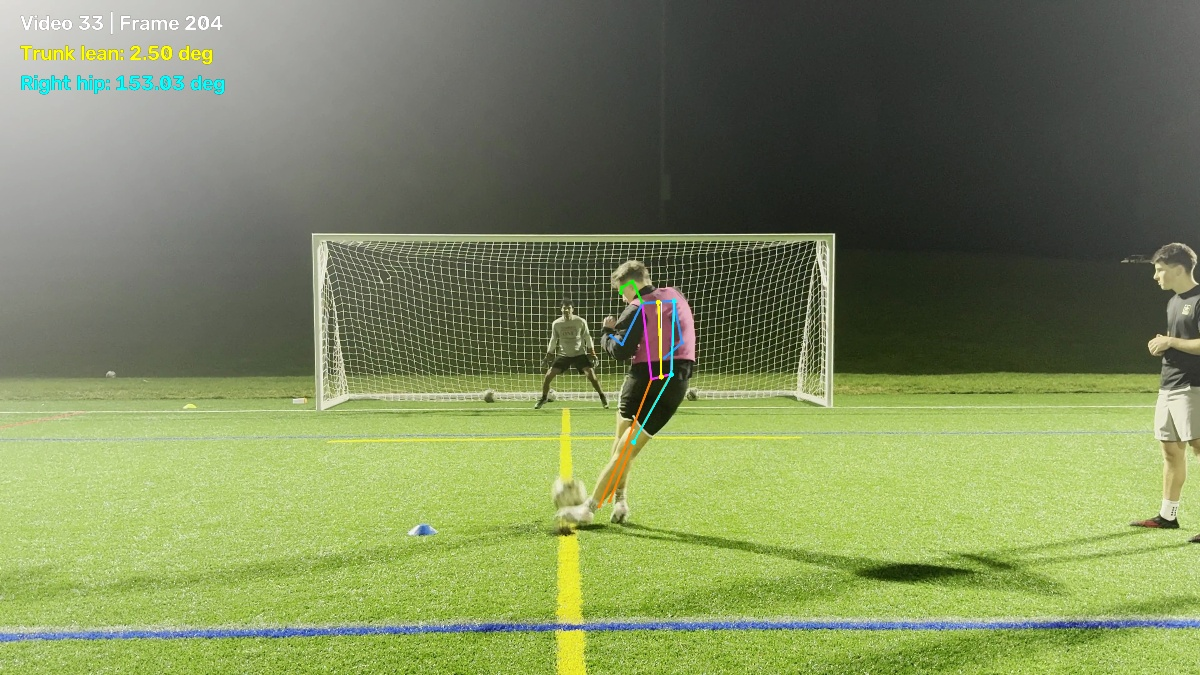

In [21]:
from pathlib import Path
import re

import cv2
import numpy as np
import pandas as pd
from IPython.display import Image, display

# CHANGE THIS NUMBER to inspect a different video
video_number = 33

# find the matching video in your labels
video_numbers = labels["video"].str.extract(
    r"-\s*(\d+)\.[^.]+$", expand=False
)
matches = labels.loc[
    pd.to_numeric(video_numbers, errors="coerce").eq(video_number)
]

if len(matches) != 1:
    raise ValueError(
        f"Expected one label row for video {video_number}; "
        f"found {len(matches)}."
    )

kick = matches.iloc[0]
video_name = kick["video"]
contact_frame = int(kick["contact_frame"])
foot = str(kick["foot"]).strip().lower()

if foot not in ["left", "right"]:
    raise ValueError(f"Invalid kicking-foot label: {foot}")

# load this video's pose measurements
pose_path = POSE_DIR / Path(video_name).stem / "pose.csv"
pose = pd.read_csv(pose_path)

#contact frame pose row
contact_pose = pose.loc[pose["frame"].eq(contact_frame)]

if len(contact_pose) != 1:
    raise ValueError(
        f"Expected one pose row at frame {contact_frame}; "
        f"found {len(contact_pose)}."
    )

row = contact_pose.iloc[0]

# sanity check that the required coords are available
joints = [
    "left_shoulder", "right_shoulder",
    "left_hip", "right_hip",
    f"{foot}_knee"
]
coordinate_columns = [
    f"{joint}_{axis}"
    for joint in joints
    for axis in ["x", "y"]
]

if not np.isfinite(
    row[coordinate_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Required joint coordinates are missing or invalid.")

# calculate shoulder and hip midpoints
shoulder_x = (row["left_shoulder_x"] + row["right_shoulder_x"]) / 2
shoulder_y = (row["left_shoulder_y"] + row["right_shoulder_y"]) / 2

hip_x = (row["left_hip_x"] + row["right_hip_x"]) / 2
hip_y = (row["left_hip_y"] + row["right_hip_y"]) / 2

#difference in hip and shoulder coords to calculate trunk lean
dx = shoulder_x - hip_x
dy = hip_y - shoulder_y

if dy <= 0:
    raise ValueError("Shoulder midpoint is not above hips; review the pose.")

#arctan to get trunk lean in degrees
trunk_lean = np.degrees(np.arctan2(abs(dx), dy))
hip_angle = row[f"{foot}_hip_angle"]

print("Video:", video_name)
print("Contact frame:", contact_frame)
print("Kicking foot:", foot)
print(f"Trunk lean: {trunk_lean:.2f} degrees")
print(f"Kicking-side hip angle: {hip_angle:.2f} degrees")

#check to make sure the model overlay works
display(contact_pose[
    ["frame", "person_detected"]
    + [f"{joint}_confidence" for joint in joints]
    + [f"{foot}_hip_angle"]
])

# Read the contact frame from the annotated video
annotated_path = pose_path.parent / "annotated.mp4"
cap = cv2.VideoCapture(str(annotated_path))

try:
    if not cap.isOpened():
        raise RuntimeError(f"Could not open {annotated_path}")

    cap.set(cv2.CAP_PROP_POS_FRAMES, contact_frame)
    success, frame = cap.read()

    if not success:
        raise RuntimeError(f"Could not read frame {contact_frame}")
finally:
    cap.release()

# Draw trunk lean
hip_mid = (round(hip_x), round(hip_y))
shoulder_mid = (round(shoulder_x), round(shoulder_y))
vertical_top = (round(hip_x), round(shoulder_y))

# White: vertical reference; yellow: trunk line
cv2.line(frame, hip_mid, vertical_top, (255, 255, 255), 3)
cv2.line(frame, hip_mid, shoulder_mid, (0, 255, 255), 5)

for point in [hip_mid, shoulder_mid]:
    cv2.circle(frame, point, 8, (0, 255, 255), -1)

# Draw the kicking-side shoulder–hip–knee angle
def joint_point(joint):
    return (
        round(row[f"{joint}_x"]),
        round(row[f"{joint}_y"])
    )

shoulder = joint_point(f"{foot}_shoulder")
hip = joint_point(f"{foot}_hip")
knee = joint_point(f"{foot}_knee")

# Cyan: hip-angle segments
cv2.line(frame, shoulder, hip, (255, 255, 0), 5)
cv2.line(frame, hip, knee, (255, 255, 0), 5)

for point in [shoulder, hip, knee]:
    cv2.circle(frame, point, 8, (255, 255, 0), -1)

# Resize after drawing to preserve coordinate alignment
height, width = frame.shape[:2]
display_width = min(width, 1200)

preview = cv2.resize(
    frame,
    (display_width, round(height * display_width / width))
)

# Add readable labels after resizing
for text, position, color in [
    (f"Video {video_number} | Frame {contact_frame}", (20, 30),
     (255, 255, 255)),
    (f"Trunk lean: {trunk_lean:.2f} deg", (20, 60),
     (0, 255, 255)),
    (f"{foot.capitalize()} hip: {hip_angle:.2f} deg", (20, 90),
     (255, 255, 0))
]:
    # Black outline helps text stand out against the image
    cv2.putText(
        preview, text, position,
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 4
    )
    cv2.putText(
        preview, text, position,
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2
    )

success, encoded = cv2.imencode(".jpg", preview)

if not success:
    raise RuntimeError("Could not encode the preview.")

display(Image(data=encoded.tobytes()))

## Mass analysis

In [23]:
#confidence threshold for model overlay 
MIN_CONFIDENCE = 0.50
metric_rows = []

#go thru all vids and the label table one row at a time to calculate trunk lean and hip angle, and check for missing or low-confidence joints
for _, kick in labels.iterrows():
    #filename, which foot they kick with, and the contact frame of the kick 
    video = kick["video"]
    foot = kick["foot"]
    contact = int(kick["contact_frame"])

    # Initialize the result dictionary for this video
    result = {
        "video": video,
        "trunk_lean_deg": np.nan,
        "kicking_hip_angle_deg": np.nan,
        "pose_review": ""
    }

    path = POSE_DIR / Path(video).stem / "pose.csv"

    #gets the pose data for the contact frame and checks for missing or low-confidence joints and to make sure it exists
    if not path.exists():
        result["pose_review"] = "Missing pose CSV"

    elif foot not in ["left", "right"]:
        result["pose_review"] = "Invalid kicking-foot label"

    else:
        #read the pose data and find the row corresponding to the contact frame
        pose_data = pd.read_csv(path)
        matches = pose_data.loc[pose_data["frame"].eq(contact)]

        if len(matches) != 1:
            result["pose_review"] = "Contact frame missing or duplicated"

        else:
            r = matches.iloc[0]

            # Trunk lean requires both shoulders and both hips
            trunk_joints = [
                "left_shoulder", "right_shoulder",
                "left_hip", "right_hip"
            ]

            #builds coord column names for trunk calculation
            trunk_columns = [
                f"{joint}_{axis}"
                for joint in trunk_joints
                for axis in ["x", "y"]
            ]

            #safety check to make sure its good and w good confidence
            trunk_ok = (
                r[trunk_columns].notna().all()
                and all(
                    r[f"{joint}_confidence"] >= MIN_CONFIDENCE
                    for joint in trunk_joints
                )
            )

            #record issues if needed (jsut initializing the list to hold any notes about issues)
            notes = []

            #trunk lean calculation!
            if trunk_ok:
                #left and right shoulder and hip midpoints 
                sx = (r["left_shoulder_x"] + r["right_shoulder_x"]) / 2
                sy = (r["left_shoulder_y"] + r["right_shoulder_y"]) / 2
                hx = (r["left_hip_x"] + r["right_hip_x"]) / 2
                hy = (r["left_hip_y"] + r["right_hip_y"]) / 2

                #difference btween right and left for shoulder and hip 
                dx, dy = sx - hx, hy - sy

                #check again to make sure the numbers make sense (make sure shoulder midpoint above hip midpoint)
                if dy > 0:
                    result["trunk_lean_deg"] = np.degrees(
                        #arctan to get angle
                        np.arctan2(abs(dx), dy)
                    )
                else:
                    notes.append("Review trunk geometry")
            else:
                notes.append("Missing or low-confidence trunk joints")

            # hip angle requires kicking-side shoulder, hip, and knee
            hip_joints = [
                #fstring adds the type of foot used (left or right)
                f"{foot}_shoulder",
                f"{foot}_hip",
                f"{foot}_knee"
            ]

            #confidence sanity check for hip angle calculation
            hip_ok = all(
                r[f"{joint}_confidence"] >= MIN_CONFIDENCE
                for joint in hip_joints
            )

            angle = r[f"{foot}_hip_angle"]

            #record if all good
            if hip_ok and pd.notna(angle) and 0 <= angle <= 180:
                result["kicking_hip_angle_deg"] = angle
            else:
                notes.append("Missing or unreliable hip angle")

            result["pose_review"] = "; ".join(notes) or "Passed numeric checks"

    metric_rows.append(result)

metrics = pd.DataFrame(metric_rows)

display(metrics)
print("\nReview summary:")
print(metrics["pose_review"].value_counts())

,video,trunk_lean_deg,kicking_hip_angle_deg,pose_review
0,pk vids - 1.MOV,5.830218,107.806519,Passed numeric checks
1,pk vids - 2.MOV,5.333093,98.698031,Passed numeric checks
2,pk vids - 3.MOV,0.001090,107.454833,Passed numeric checks
3,pk vids - 4.MOV,0.006118,119.321100,Passed numeric checks
4,pk vids - 5.MOV,5.559232,110.520341,Passed numeric checks
5,pk vids - 6.MOV,6.094664,139.071708,Passed numeric checks
6,pk vids - 7.MOV,4.032665,120.557930,Passed numeric checks
7,pk vids - 8.MOV,0.324657,97.343907,Passed numeric checks
8,pk vids - 9.MOV,1.481289,120.995118,Passed numeric checks
9,pk vids - 10.MOV,1.312685,106.414106,Passed numeric checks



Review summary:
pose_review
Passed numeric checks    35
Name: count, dtype: int64


In [ ]:
# Match pose measurements to the manual labels by filename, keeping every labeled kick
analysis_data = labels.copy().merge(
    metrics,
    on="video",
    how="left",
    validate="one_to_one"
)

# bring in only speed, avoiding duplicate label columns
analysis_data = analysis_data.merge(
    speeds[["video", "estimated_speed_mph"]],
    on="video",
    how="left",
    validate="one_to_one"
)

# keeping any technique notes (if needed)
if "technique_note" not in analysis_data.columns:
    analysis_data["technique_note"] = ""


# Confirm all three analysis variables are numeric and complete
analysis_columns = [
    "estimated_speed_mph",
    "trunk_lean_deg",
    "kicking_hip_angle_deg"
]

analysis_data[analysis_columns] = analysis_data[
    analysis_columns
].apply(pd.to_numeric, errors="coerce")

print("Total kicks:", len(analysis_data))
print("\nMissing analysis values:")
print(analysis_data[analysis_columns].isna().sum())

display(analysis_data[[
    "video",
    "foot",
    "estimated_speed_mph",
    "trunk_lean_deg",
    "kicking_hip_angle_deg",
    "technique_note"
]].head())

Total kicks: 35

Missing analysis values:
estimated_speed_mph      0
trunk_lean_deg           0
kicking_hip_angle_deg    0
dtype: int64


,video,foot,estimated_speed_mph,trunk_lean_deg,kicking_hip_angle_deg,technique_note
0,pk vids - 1.MOV,right,44.609506,5.830218,107.806519,
1,pk vids - 2.MOV,right,47.484533,5.333093,98.698031,
2,pk vids - 3.MOV,left,50.759483,0.001090,107.454833,
3,pk vids - 4.MOV,right,36.795534,0.006118,119.321100,
4,pk vids - 5.MOV,right,42.058907,5.559232,110.520341,


# Data Analysis

In [26]:
# summarize the outcome and two predictors across kicks
variables = [
    "estimated_speed_mph",
    "trunk_lean_deg",
    "kicking_hip_angle_deg"
]

display(analysis_data[variables].describe().round(2))

,estimated_speed_mph,trunk_lean_deg,kicking_hip_angle_deg
count,35.00,35.00,35.00
mean,45.27,4.13,117.70
std,7.01,3.39,14.04
min,31.57,0.00,96.13
25%,40.69,1.40,107.63
50%,44.61,3.51,114.25
75%,50.78,6.09,128.96
max,59.48,13.78,153.03
